# LLaVA Benchmark Analysis

This notebook visualizes the performance of different LLaVA model variants across multiple benchmarks.

In [129]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
import os

# Set plot style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (15, 8)

In [130]:
# Directory paths
LMMS_EVAL_DIR = Path.home() / "multimodal_finetuned_representations/evals/llava-1.5-7b/lmms_eval"

# Reference scores from LLaVA-1.5-7B paper (MODEL_ZOO.md)
REFERENCE_SCORES = {
    'scienceqa_img': 66.8,
    'mme': 1510.7,
    'textvqa_val': 58.2,
    'pope': 85.9,
    'gqa': 62.0,
    'mmbench_en_dev': 64.3,
    'mmbench_cn_dev': 58.3,
    'llava_in_the_wild': 65.4,
    'seedbench': 58.6,  # SEEDBench_IMG
    'vqav2_val': 78.5,
    'vizwiz_vqa_val': 50.0,
    'mmvet': 31.1
}

MODELS_TO_LOAD = {
    # "LLaVA Layers 0-8": "single/l11p_llava-v1.5-7b-lbasile-layers-0-8-step-10000",
    # "LLaVA Layers 8-16": "single/l11p_llava-v1.5-7b-lbasile-layers-8-16-step-10000",
    # "Finetuned": "finetuned_pretrained/llava-hf_llava-1.5-7b-hf_finetuned",
    "LLaVA 7B Full": "single/l11p_llava-7b-lbasile",
    "Original LLaVA 1.5-7B": "single/llava-hf_llava-1.5-7b-hf",
    "LLaVA 7B 10000": "single/l11p_llava-v1.5-7b-lbasile-full-step-10000"
}

BENCHMARKS = {
    'ScienceQA': {'dir': 'scienceqa_img', 'key': 'exact_match,none'},
    'MME': {'dir': 'mme', 'key': 'total'},
    'TextVQA': {'dir': 'textvqa_val', 'key': 'exact_match,none'},
    'POPE': {'dir': 'pope', 'key': 'pope_f1_score,none'},
    'GQA': {'dir': 'gqa', 'key': 'exact_match,none'},
    'MMBench': {'dir': 'mmbench_en_dev', 'key': 'gpt_eval_score,none'},
    'MMBench-CN': {'dir': 'mmbench_cn_dev', 'key': 'gpt_eval_score,none'},
    'LLaVA-Wild': {'dir': 'llava_in_the_wild', 'key': 'gpt_eval_llava_all,none'},
    'SEED-Bench': {'dir': 'seedbench', 'key': 'seed_all,none'},
    'VQAv2': {'dir': 'vqav2_val', 'key': 'exact_match,none'},
    'VizWiz': {'dir': 'vizwiz_vqa_val', 'key': 'exact_match,none'},
}

# Function to load results
def load_results(benchmark_dir):
    if not benchmark_dir.exists():
        return None
    results_file = next((f for f in os.listdir(benchmark_dir) if 'results' in f and f.endswith('.jsonl')), None)
    if results_file:
        with open(benchmark_dir / results_file, 'r') as f:
            return [json.loads(line) for line in f]
    return None

def get_scores():
    scores_dict = {}
    for bench_name, bench_info in BENCHMARKS.items():
        results = load_results(LMMS_EVAL_DIR / bench_info['dir'])
        if not results:
            print(f"No results found for {bench_name}")
            continue
        for model_name, model_id in MODELS_TO_LOAD.items():
            for res in results:
                if res['experiment_name'] == model_id:
                    if bench_name == 'MME':
                        score = res.get('mme_perception_score,none', 0)# + res.get('mme_cognition_score,none', 0)
                    else:
                        score = res[bench_info['key']]
                    if bench_name != 'MME' and bench_name != 'MMBench' and bench_name != "LLaVA-Wild" and bench_name != "MMBench-CN":
                        score *= 100
                    scores_dict[(bench_name, model_name)] = score

    data = {'Benchmark': [], 'Model': [], 'Score': []}
    for (bench_name, model_name), score in scores_dict.items():
        data['Benchmark'].append(bench_name)
        data['Model'].append(model_name)
        data['Score'].append(score)

    return pd.DataFrame(data)

df = get_scores()

# Add reference scores to dataframe
benchmark_name_map = {v['dir']: k for k, v in BENCHMARKS.items()}
for bench_dir, ref_score in REFERENCE_SCORES.items():
    bench_name = benchmark_name_map.get(bench_dir)
    if bench_name and bench_name in df['Benchmark'].values:
        df = pd.concat([df, pd.DataFrame({'Benchmark': [bench_name], 'Model': ['Paper'], 'Score': [ref_score]})], ignore_index=True)

# Normalize function for plotting
def normalize_score(row):
    if row["Benchmark"] == "MME":
        return row["Score"] / 20.0  # Normalize MME scores to a 0-100 scale
    return row["Score"]

df["Score_Normalized"] = df.apply(normalize_score, axis=1)

# Pivot table for clean viewing
pivot_df = df.pivot(index="Benchmark", columns="Model", values="Score")
if not pivot_df.empty:
    pivot_df = pivot_df[list(MODELS_TO_LOAD.keys())] # Reorder
display(pivot_df)


Model,LLaVA 7B Full,Original LLaVA 1.5-7B,LLaVA 7B 10000
Benchmark,,,
GQA,60.450000,59.800000,61.550000
LLaVA-Wild,54.200000,55.000000,54.800000
MMBench,70.618557,69.243986,71.134021
MMBench-CN,60.824742,58.247423,63.745704
MME,1446.862445,1452.548219,1370.371048
POPE,81.477398,82.095136,81.436464
SEED-Bench,65.500000,64.950000,66.300000
ScienceQA,67.526029,66.137828,67.526029
TextVQA,47.575000,47.300000,49.290000


In [131]:
# Print Table in Markdown
print("### Comprehensive Performance Table")
if not pivot_df.empty:
    print(pivot_df.to_markdown())

### Comprehensive Performance Table
| Benchmark   |   LLaVA 7B Full |   Original LLaVA 1.5-7B |   LLaVA 7B 10000 |
|:------------|----------------:|------------------------:|-----------------:|
| GQA         |         60.45   |                 59.8    |          61.55   |
| LLaVA-Wild  |         54.2    |                 55      |          54.8    |
| MMBench     |         70.6186 |                 69.244  |          71.134  |
| MMBench-CN  |         60.8247 |                 58.2474 |          63.7457 |
| MME         |       1446.86   |               1452.55   |        1370.37   |
| POPE        |         81.4774 |                 82.0951 |          81.4365 |
| SEED-Bench  |         65.5    |                 64.95   |          66.3    |
| ScienceQA   |         67.526  |                 66.1378 |          67.526  |
| TextVQA     |         47.575  |                 47.3    |          49.29   |
| VQAv2       |         50.565  |                 49.55   |          50.13   |
| VizWiz      | 

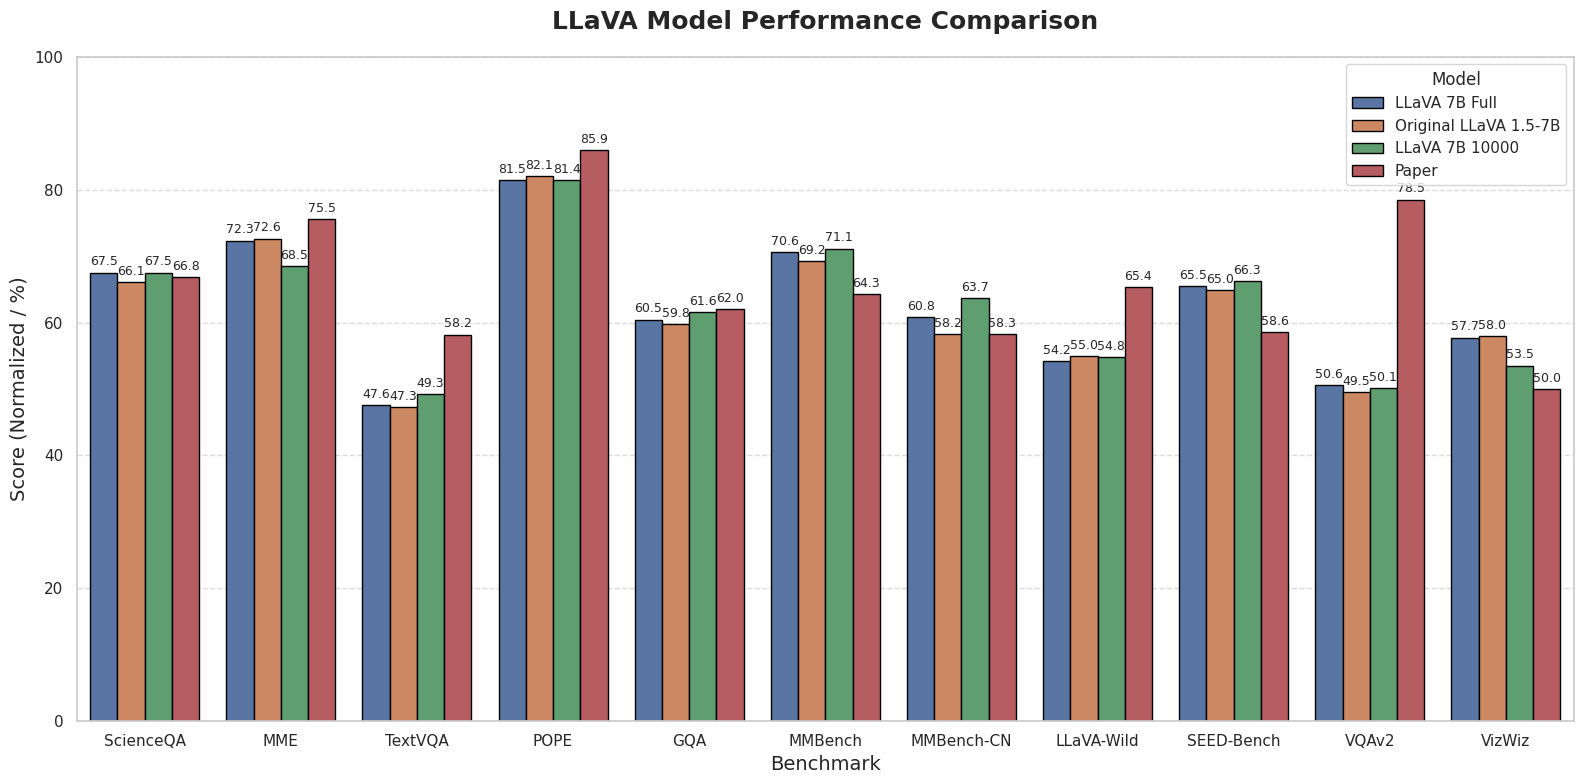

In [132]:
# Bar Plot
plt.figure(figsize=(16, 8))
plot = sns.barplot(
    data=df,
    x="Benchmark",
    y="Score_Normalized",
    hue="Model",
    # palette=["#a1c9f4", "#ffb482", "#8de5a1", "#d9b3d9", "#f7a35c"],  # Blue, Orange, Green, Purple, Yellow pastel
    edgecolor="black",
    linewidth=1
)

plt.title("LLaVA Model Performance Comparison", fontsize=18, fontweight='bold', pad=20)
plt.ylabel("Score (Normalized / %)", fontsize=14)
plt.xlabel("Benchmark", fontsize=14)
plt.ylim(0, 100)
plt.legend(title="Model", title_fontsize=12, fontsize=11, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add value labels
if hasattr(plot, 'containers'):
    for container in plot.containers:
        plot.bar_label(container, fmt='%.1f', padding=3, fontsize=9)

plt.tight_layout()
plt.savefig("benchmarks_comparison.png", dpi=300)
plt.show()


# Radar Plot

This section compares the models across all benchmarks using a radar chart. scores are normalized (0-1).

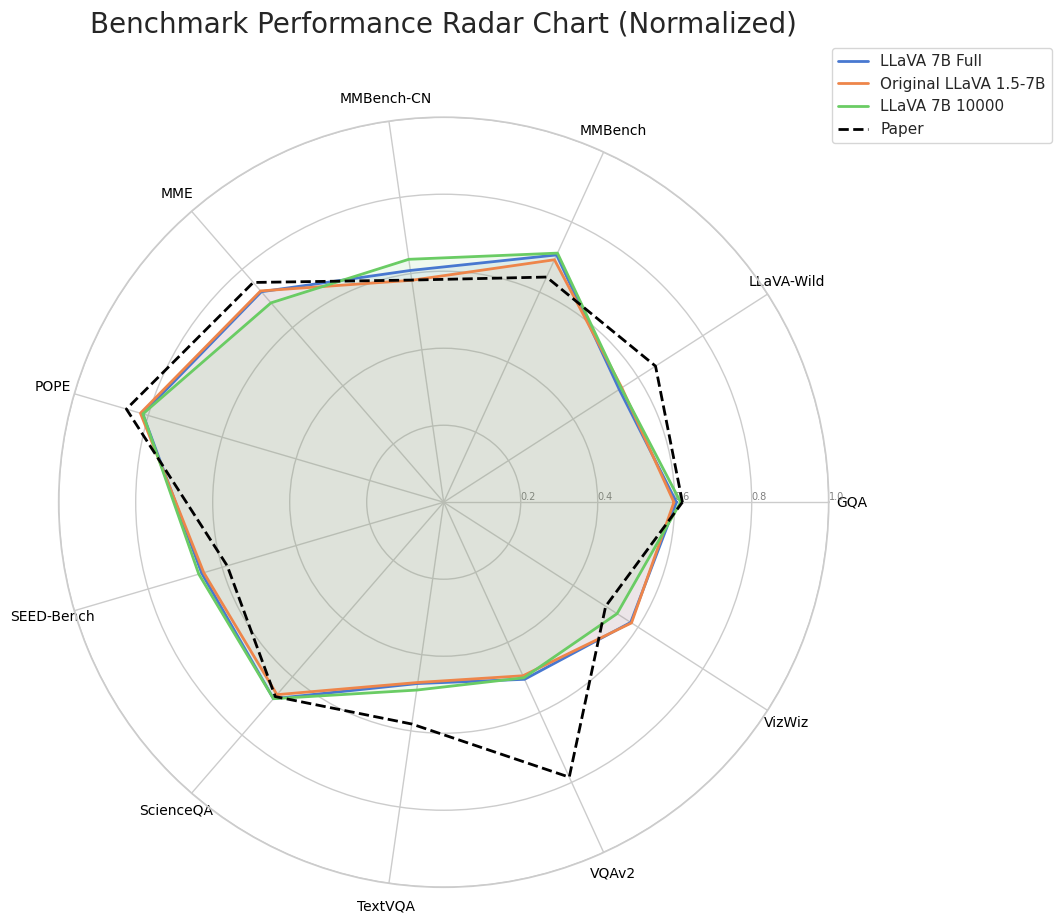

In [133]:
import numpy as np
from math import pi

# Radar Plot Configuration
# Normalize all scores to 0-1 scale based on known max values or 100
RADAR_BENCHMARKS = list(pivot_df.index)
N = len(RADAR_BENCHMARKS)

# Compute angles for each axis
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # Close the loop

# Initialize the spider plot
plt.figure(figsize=(10, 10))
ax = plt.subplot(111, polar=True)

# Draw one axe per variable + labels
plt.xticks(angles[:-1], RADAR_BENCHMARKS, color='black', size=10)

# Vertical labels
ax.set_rlabel_position(0)
plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ["0.2", "0.4", "0.6", "0.8", "1.0"], color="grey", size=7)
plt.ylim(0, 1)

# Plot data for each model
# Get list of models (excluding Paper if you want, or include it)
models_to_plot = [m for m in pivot_df.columns if m != 'Paper'] # Example: plot only models, not paper ref
# models_to_plot = pivot_df.columns # Or plot everything including Paper

# Define a color palette
colors = sns.color_palette("muted", len(models_to_plot))

for i, model in enumerate(models_to_plot):
    values = []
    for bench in RADAR_BENCHMARKS:
        # Get normalized score for this model & benchmark
        # We need to re-normalize because df['Score_Normalized'] is already 0-100 logic but some are 0-1
        # Actually in this notebook df['Score_Normalized'] seems to be 0-100 based on previous cells
        # Let's use the pivot_df directly which has raw scores (except MME might be large)
        
        # Let's use the 'df' which has 'Score_Normalized' column
        # Filter df for specific model and benchmark
        score_row = df[(df['Model'] == model) & (df['Benchmark'] == bench)]
        if not score_row.empty:
            score = score_row['Score_Normalized'].values[0]
            # Normalize to 0-1 for radar plot
            values.append(score / 100.0) 
        else:
            values.append(0)
            
    values += values[:1] # Close the loop
    
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=model, color=colors[i])
    ax.fill(angles, values, color=colors[i], alpha=0.1)

# Add Paper reference as a specific line if it exists
if 'Paper' in df['Model'].unique():
    values = []
    for bench in RADAR_BENCHMARKS:
        score_row = df[(df['Model'] == 'Paper') & (df['Benchmark'] == bench)]
        if not score_row.empty:
            score = score_row['Score_Normalized'].values[0]
            values.append(score / 100.0)
        else:
            values.append(0)
    values += values[:1]
    ax.plot(angles, values, linewidth=2, linestyle='--', label='Paper', color='black')


plt.title('Benchmark Performance Radar Chart (Normalized)', size=20, y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

plt.show()